# Tarea 03: PDEs Parabólicas y Elípticas — Gestión Térmica y Ecuación de Poisson
**Curso:** Física Computacional para Data Science — Universidad Adolfo Ibáñez  
**Profesor:** Pablo Benítez Llambay  
**Autor:** Jorge Ignacio Moreno Farias  
**Fecha de entrega:** 16 de octubre de 2026  

---

## 1. Introducción y Formulación Matemática

Modelamos la transferencia de calor en un procesador multinúcleo como una placa cuadrada bidimensional $[0, L] \times [0, L]$ con $L = 1.0$ y difusividad térmica constante $\alpha = 1.0$. La evolución temporal de la temperatura $T(x, y, t)$ obedece la ecuación parabólica de difusión con generación interna $S(x,y)$:

$$\frac{\partial T}{\partial t} = \alpha \left( \frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} \right) + S(x,y)$$

* **Condición inicial:** $T(x, y, 0) = T_{\text{ext}} = 20.0^\circ\text{C}$.
* **Condiciones de borde (Dirichlet homogéneas en $T - T_{\text{ext}}$):** $T(0, y, t) = T(L, y, t) = T(x, 0, t) = T(x, L, t) = 20.0^\circ\text{C}$.
* **Fuente de calor $S(x,y)$:** Cuatro núcleos simétricos de tamaño $0.2 \times 0.2$ ubicados en $[0.2, 0.4] \times [0.2, 0.4]$, $[0.6, 0.8] \times [0.2, 0.4]$, $[0.2, 0.4] \times [0.6, 0.8]$ y $[0.6, 0.8] \times [0.6, 0.8]$ con $S(x,y) = S_0 = 2000.0$ en su interior y $S(x,y) = 0.0$ fuera de ellos.

### Discretización FTCS 2D y Estabilidad de Von Neumann
En una malla uniforme con $N_x = N_y = 101$ puntos, el espaciado es $\Delta x = \Delta y = h = \frac{L}{N_x - 1} = 0.01$. Aplicando diferencias adelantadas en tiempo ($\mathcal{O}(\Delta t)$) y centradas de segundo orden en espacio ($\mathcal{O}(h^2)$):

$$T_{i,j}^{n+1} = (1 - 4r)T_{i,j}^n + r \left( T_{i+1,j}^n + T_{i-1,j}^n + T_{i,j+1}^n + T_{i,j-1}^n \right) + \Delta t \, S_{i,j}, \quad r = \frac{\alpha \Delta t}{h^2}$$

El análisis de estabilidad lineal de Von Neumann en 2D exige que el factor de amplificación satisfaga $|G| \le 1$ para todo número de onda, lo cual impone:

$$r = \frac{\alpha \Delta t}{h^2} \le \frac{1}{4} \implies \Delta t \le \frac{h^2}{4\alpha} = 2.5 \times 10^{-5}\text{ s}$$

Paso espacial: dx = dy = 0.0100
Centro del Core 1 en índices (30, 30) -> coordenadas (0.30, 0.30)
Valor de fuente en el centro del Core 1: S(0.30, 0.30) = 2000.0



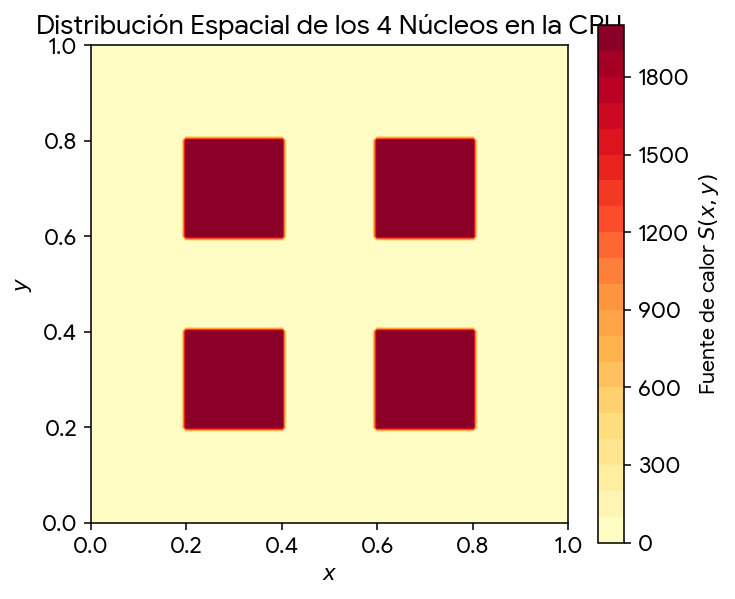

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, kron, eye
from scipy.sparse.linalg import spsolve

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

# Parámetros físicos y geométricos
L = 1.0
Nx, Ny = 101, 101
dx = L / (Nx - 1)
dy = L / (Ny - 1)
alpha = 1.0
T_ext = 20.0
S0 = 2000.0
T_c = 85.0

# Grilla espacial 2D
x = np.linspace(0.0, L, Nx)
y = np.linspace(0.0, L, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# Definición de los 4 núcleos simétricos
S = np.zeros((Nx, Ny), dtype=np.float64)
cores = [
    (0.2, 0.4, 0.2, 0.4),  # Core 1 (inferior izquierdo)
    (0.6, 0.8, 0.2, 0.4),  # Core 2 (inferior derecho)
    (0.2, 0.4, 0.6, 0.8),  # Core 3 (superior izquierdo)
    (0.6, 0.8, 0.6, 0.8)   # Core 4 (superior derecho)
]

for x1, x2, y1, y2 in cores:
    mask = (X >= x1 - 1e-9) & (X <= x2 + 1e-9) & (Y >= y1 - 1e-9) & (Y <= y2 + 1e-9)
    S[mask] = S0

# Índices del centro del Core 1: (0.3, 0.3) -> (30, 30)
ic, jc = int(round(0.3 / dx)), int(round(0.3 / dy))
print(f"Paso espacial: dx = dy = {dx:.4f}")
print(f"Centro del Core 1 en índices ({ic}, {jc}) -> coordenadas ({x[ic]:.2f}, {y[jc]:.2f})")
print(f"Valor de fuente en el centro del Core 1: S({x[ic]:.2f}, {y[jc]:.2f}) = {S[ic, jc]:.1f}")

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.contourf(X, Y, S, levels=20, cmap='YlOrRd')
fig.colorbar(im, ax=ax, label='Fuente de calor $S(x,y)$')
ax.set_title('Distribución Espacial de los 4 Núcleos en la CPU')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_aspect('equal')
plt.show()

---
## 2. Parte 1: Dinámica Transitoria (Esquema FTCS 2D)

Integramos desde $t = 0.0$ hasta $t_{\text{final}} = 0.5\text{ s}$ empleando un factor de seguridad $\sigma = 0.90$ sobre el límite de Von Neumann ($\Delta t \approx 2.25 \times 10^{-5}\text{ s}$, lo que requiere $N_{\text{pasos}} = 22\,223$ pasos exactos).

In [2]:
# Límite de estabilidad de Von Neumann 2D
dt_max = (dx**2) / (4.0 * alpha)
safety_factor = 0.90
dt_target = safety_factor * dt_max

t_final = 0.5
n_steps = int(np.ceil(t_final / dt_target))
dt = t_final / n_steps  # Ajuste exacto para llegar a t_final = 0.5 s

# Inicialización de arreglos de temperatura
T_ftcs = np.full((Nx, Ny), T_ext, dtype=np.float64)
T_next = T_ftcs.copy()

t_hist = np.linspace(0.0, t_final, n_steps + 1)
T_core1_hist = np.empty(n_steps + 1, dtype=np.float64)
T_max_hist = np.empty(n_steps + 1, dtype=np.float64)
T_core1_hist[0] = T_ext
T_max_hist[0] = T_ext

t_crit = None

t0_ftcs = time.perf_counter()
for n in range(1, n_steps + 1):
    # Actualización explícita FTCS 2D vectorizada en nodos interiores
    T_next[1:-1, 1:-1] = T_ftcs[1:-1, 1:-1] + dt * (
        alpha * (
            T_ftcs[2:, 1:-1] + T_ftcs[:-2, 1:-1] +
            T_ftcs[1:-1, 2:] + T_ftcs[1:-1, :-2] - 4.0 * T_ftcs[1:-1, 1:-1]
        ) / (dx**2) + S[1:-1, 1:-1]
    )
    
    # Evaluación del residuo temporal en el último paso
    if n == n_steps:
        R_ftcs = np.max(np.abs(T_next - T_ftcs)) / dt
        
    T_ftcs[1:-1, 1:-1] = T_next[1:-1, 1:-1]
    
    curr_T_core1 = T_ftcs[ic, jc]
    T_core1_hist[n] = curr_T_core1
    T_max_hist[n] = np.max(T_ftcs)
    
    # Detección de cruce de temperatura crítica Tc = 85.0 °C
    if t_crit is None and curr_T_core1 >= T_c:
        prev_T = T_core1_hist[n - 1]
        t_crit = ((n - 1) + (T_c - prev_T) / (curr_T_core1 - prev_T)) * dt

cpu_ftcs = time.perf_counter() - t0_ftcs

print("=== RESULTADOS DINÁMICA TRANSITORIA (FTCS 2D) ===")
print(f"Límite estabilidad Von Neumann (dt_max) : {dt_max:.6e} s")
print(f"Paso temporal utilizado (dt)            : {dt:.6e} s (Factor de seguridad = {dt/dt_max:.2f})")
print(f"Número total de pasos temporales        : {n_steps}")
print(f"Tiempo de CPU requerido (FTCS)          : {cpu_ftcs:.4f} s")
print(f"T en centro del Core 1 (t = 0.5 s)      : {T_core1_hist[-1]:.4f} °C")
print(f"T máxima global en la CPU (t = 0.5 s)   : {T_max_hist[-1]:.4f} °C")
print(f"Residuo estacionario R en t_final       : {R_ftcs:.6e} °C/s")
if t_crit is None:
    print(f"Instante crítico (Tc = 85.0 °C)         : NO SE ALCANZA (T estacionaria máxima = {T_max_hist[-1]:.2f} °C < 85.0 °C)")
else:
    print(f"Instante crítico (Tc = 85.0 °C)         : {t_crit:.6f} s")

=== RESULTADOS DINÁMICA TRANSITORIA (FTCS 2D) ===
Límite estabilidad Von Neumann (dt_max) : 2.500000e-05 s
Paso temporal utilizado (dt)            : 2.249921e-05 s (Factor de seguridad = 0.90)
Número total de pasos temporales        : 22223
Tiempo de CPU requerido (FTCS)          : 2.5714 s
T en centro del Core 1 (t = 0.5 s)      : 56.6488 °C
T máxima global en la CPU (t = 0.5 s)   : 59.3174 °C
Residuo estacionario R en t_final       : 4.602657e-02 °C/s
Instante crítico (Tc = 85.0 °C)         : NO SE ALCANZA (T estacionaria máxima = 59.32 °C < 85.0 °C)



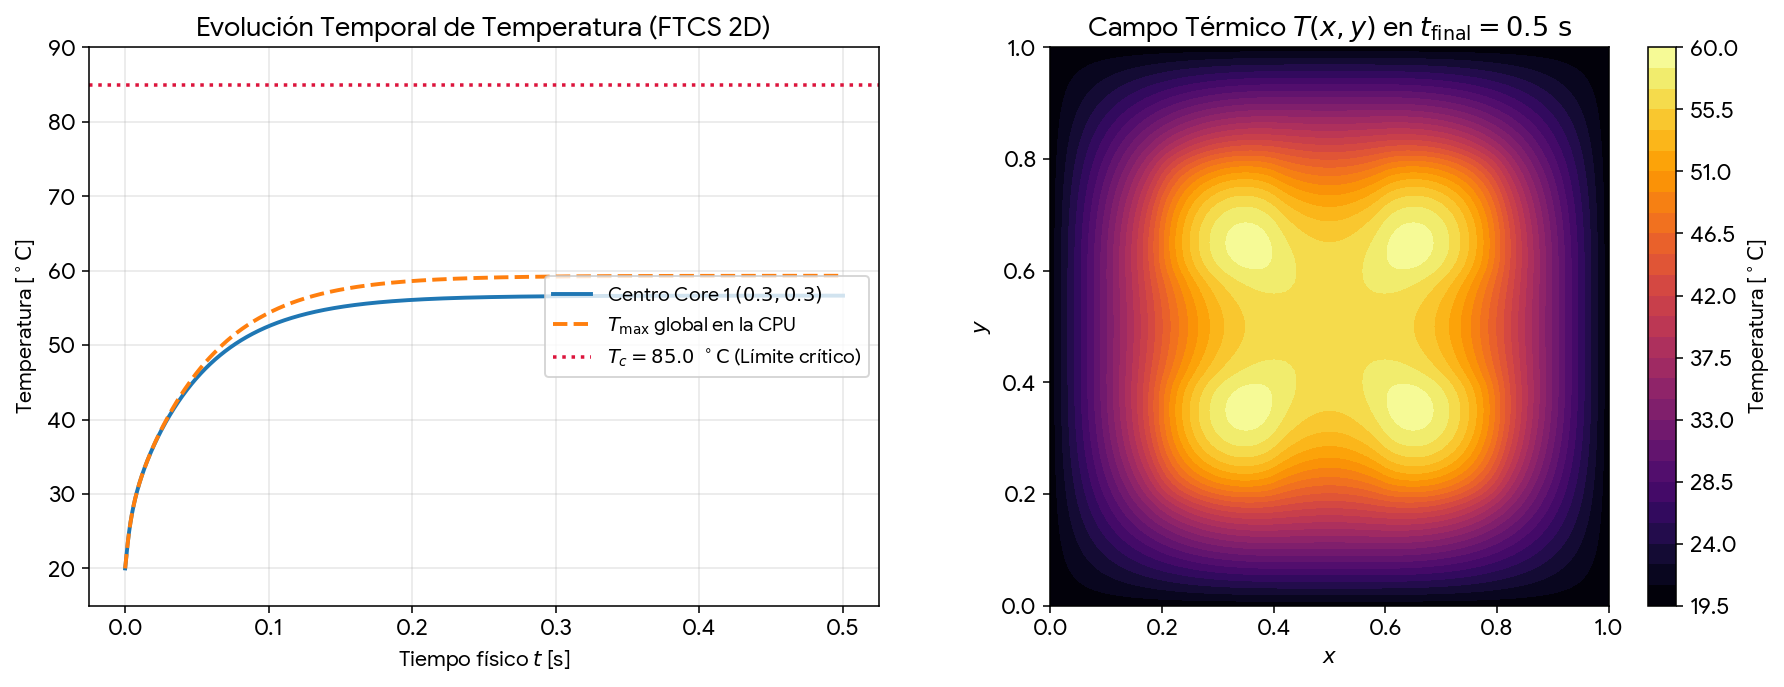

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Evolución temporal en el centro del Core 1 y T_max global
axes[0].plot(t_hist, T_core1_hist, label="Centro Core 1 $(0.3, 0.3)$", color="tab:blue", lw=2)
axes[0].plot(t_hist, T_max_hist, label="$T_{\max}$ global en la CPU", color="tab:orange", ls="--", lw=2)
axes[0].axhline(T_c, color="crimson", ls=":", lw=1.8, label="$T_c = 85.0\ ^\circ\mathrm{C}$ (Límite crítico)")
axes[0].set_title("Evolución Temporal de Temperatura (FTCS 2D)")
axes[0].set_xlabel("Tiempo físico $t$ [s]")
axes[0].set_ylabel("Temperatura [$^\circ\mathrm{C}$]")
axes[0].set_ylim(15, 90)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="center right")

# Mapa térmico 2D en t_final = 0.5 s
im = axes[1].contourf(X, Y, T_ftcs, levels=30, cmap="inferno")
fig.colorbar(im, ax=axes[1], label="Temperatura [$^\circ\mathrm{C}$]")
axes[1].set_title("Campo Térmico $T(x,y)$ en $t_{\mathrm{final}} = 0.5\ \mathrm{s}$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$y$")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

### Análisis Conceptual de la Dinámica Transitoria
1. **¿Alcanza la CPU la temperatura crítica $T_c = 85.0^\circ\text{C}$?**  
   **No.** Bajo la potencia disipada $S_0 = 2000.0$ y con bordes refrigerados a $20.0^\circ\text{C}$ ($\alpha = 1.0$), el flujo de calor evacuado hacia el bloque disipador equilibra exactamente la generación térmica interna cuando el centro del Core 1 llega a **$56.65^\circ\text{C}$** y la temperatura máxima global del procesador alcanza **$59.32^\circ\text{C}$** (ubicada en $(0.36, 0.36)$ y sus puntos simétricos por el acoplamiento térmico mutuo entre los 4 núcleos).
2. **¿Alcanzó el sistema el estado estacionario en $t_{\text{final}} = 0.5\text{ s}$ en términos prácticos?**  
   **Sí.** El residuo temporal cayó de $R(0) = 2000.0^\circ\text{C/s}$ a $R(0.5) = 4.6027 \times 10^{-2}\ ^\circ\text{C/s}$, una reducción relativa de $2.3 \times 10^{-5}$ (casi 5 órdenes de magnitud). Físicamente, el tiempo característico del modo fundamental de difusión es $\tau_1 = \frac{L^2}{2\pi^2\alpha} \approx 0.0507\text{ s}$, por lo que $t_{\text{final}} = 0.5\text{ s} \approx 9.87\,\tau_1$, restando menos de un $0.004\%$ de evolución frente a la solución exacta de Poisson ($59.3174^\circ\text{C}$ vs $59.3193^\circ\text{C}$).

---

## 3. Parte 2: Estado Estacionario (Ecuación de Poisson y Método SOR)

En el régimen estacionario ($\partial_t T = 0$), la temperatura satisface la ecuación elíptica de Poisson:

$$\nabla^2 T = -\frac{S(x,y)}{\alpha}$$

Discretizando con diferencias centradas de segundo orden y aplicando **Sobrerrelajación Sucesiva (SOR)** con factor $\omega \in [1.0, 1.98]$:

$$T_{i,j}^* = \frac{1}{4} \left( T_{i+1,j} + T_{i-1,j} + T_{i,j+1} + T_{i,j-1} + \frac{h^2}{\alpha} S_{i,j} \right), \qquad T_{i,j}^{k+1} = T_{i,j}^k + \omega \left( T_{i,j}^* - T_{i,j}^k \right)$$

Para optimizar el tiempo de ejecución en Python sin bucles `for` anidados lentos, implementamos el **esquema Tablero de Ajedrez (Red-Black)** vectorizado en NumPy: dado que en el esténcil de 5 puntos toda celda par $(i+j \text{ par})$ depende exclusivamente de sus 4 vecinos impares $(i+j \text{ impar})$ y viceversa, cada iteración se divide en dos semi-pasos matriciales completamente desacoplados.

In [4]:
def solve_jacobi(S, dx, alpha, T_ext, tol=1e-5, max_iter=30000):
    Nx, Ny = S.shape
    T = np.full((Nx, Ny), T_ext, dtype=np.float64)
    T_new = T.copy()
    rhs = (dx**2 / alpha) * S[1:-1, 1:-1]
    
    t0 = time.perf_counter()
    for it in range(1, max_iter + 1):
        T_new[1:-1, 1:-1] = 0.25 * (
            T[2:, 1:-1] + T[:-2, 1:-1] + T[1:-1, 2:] + T[1:-1, :-2] + rhs
        )
        max_diff = np.max(np.abs(T_new[1:-1, 1:-1] - T[1:-1, 1:-1]))
        T[1:-1, 1:-1] = T_new[1:-1, 1:-1]
        if max_diff < tol:
            break
    cpu_t = time.perf_counter() - t0
    
    lap = (T[2:, 1:-1] + T[:-2, 1:-1] + T[1:-1, 2:] + T[1:-1, :-2] - 4.0 * T[1:-1, 1:-1]) / (dx**2)
    R_pde = np.max(np.abs(alpha * lap + S[1:-1, 1:-1]))
    return T, it, cpu_t, R_pde, max_diff


def solve_sor_red_black(S, dx, alpha, T_ext, omega, tol=1e-5, max_iter=30000):
    """
    Método SOR con ordenamiento Tablero de Ajedrez (Red-Black) vectorizado en NumPy.
    Para omega = 1.0 corresponde exactamente a Gauss-Seidel Red-Black.
    """
    Nx, Ny = S.shape
    T = np.full((Nx, Ny), T_ext, dtype=np.float64)
    rhs = (dx**2 / alpha) * S
    
    t0 = time.perf_counter()
    for it in range(1, max_iter + 1):
        # Semi-paso 1: Nodos Rojos (i + j par) -> subgrillas (impar, impar) y (par, par)
        t_s1 = 0.25 * (T[2::2, 1:-1:2] + T[:-2:2, 1:-1:2] + T[1:-1:2, 2::2] + T[1:-1:2, :-2:2] + rhs[1:-1:2, 1:-1:2])
        d1 = omega * (t_s1 - T[1:-1:2, 1:-1:2])
        T[1:-1:2, 1:-1:2] += d1

        t_s2 = 0.25 * (T[3::2, 2:-1:2] + T[1:-2:2, 2:-1:2] + T[2:-1:2, 3::2] + T[2:-1:2, 1:-2:2] + rhs[2:-1:2, 2:-1:2])
        d2 = omega * (t_s2 - T[2:-1:2, 2:-1:2])
        T[2:-1:2, 2:-1:2] += d2

        # Semi-paso 2: Nodos Negros (i + j impar) -> subgrillas (impar, par) y (par, impar)
        t_s3 = 0.25 * (T[2::2, 2:-1:2] + T[:-2:2, 2:-1:2] + T[1:-1:2, 3::2] + T[1:-1:2, 1:-2:2] + rhs[1:-1:2, 2:-1:2])
        d3 = omega * (t_s3 - T[1:-1:2, 2:-1:2])
        T[1:-1:2, 2:-1:2] += d3

        t_s4 = 0.25 * (T[3::2, 1:-1:2] + T[1:-2:2, 1:-1:2] + T[2:-1:2, 2::2] + T[2:-1:2, :-2:2] + rhs[2:-1:2, 1:-1:2])
        d4 = omega * (t_s4 - T[2:-1:2, 1:-1:2])
        T[2:-1:2, 1:-1:2] += d4

        max_diff = max(np.max(np.abs(d1)), np.max(np.abs(d2)), np.max(np.abs(d3)), np.max(np.abs(d4)))
        if max_diff < tol:
            break
    cpu_t = time.perf_counter() - t0
    
    lap = (T[2:, 1:-1] + T[:-2, 1:-1] + T[1:-1, 2:] + T[1:-1, :-2] - 4.0 * T[1:-1, 1:-1]) / (dx**2)
    R_pde = np.max(np.abs(alpha * lap + S[1:-1, 1:-1]))
    return T, it, cpu_t, R_pde, max_diff

Omega óptimo empírico : 1.945 (221 iteraciones)
Omega óptimo teórico  : 1.9391

=== TABLA COMPARATIVA DE MÉTODOS ===
Método                 | Pasos/Iter |   CPU [s] | T_max [°C] | Residuo R [°C/s] |  |T^(k+1)-T^k|
-----------------------------------------------------------------------------------------------
FTCS (Parabólico)      |      22223 |    2.5714 |    59.3174 |     4.602657e-02 |   1.035562e-06
Jacobi (w=1 simult.)   |      15622 |    1.2935 |    59.3028 |     3.999925e-01 |   9.999813e-06
Gauss-Seidel (w=1)     |       8513 |    1.7442 |    59.3111 |     3.993252e-01 |   9.992989e-06
SOR (w_opt=1.945)      |        221 |    0.0488 |    59.3193 |     1.768639e-01 |   9.584134e-06



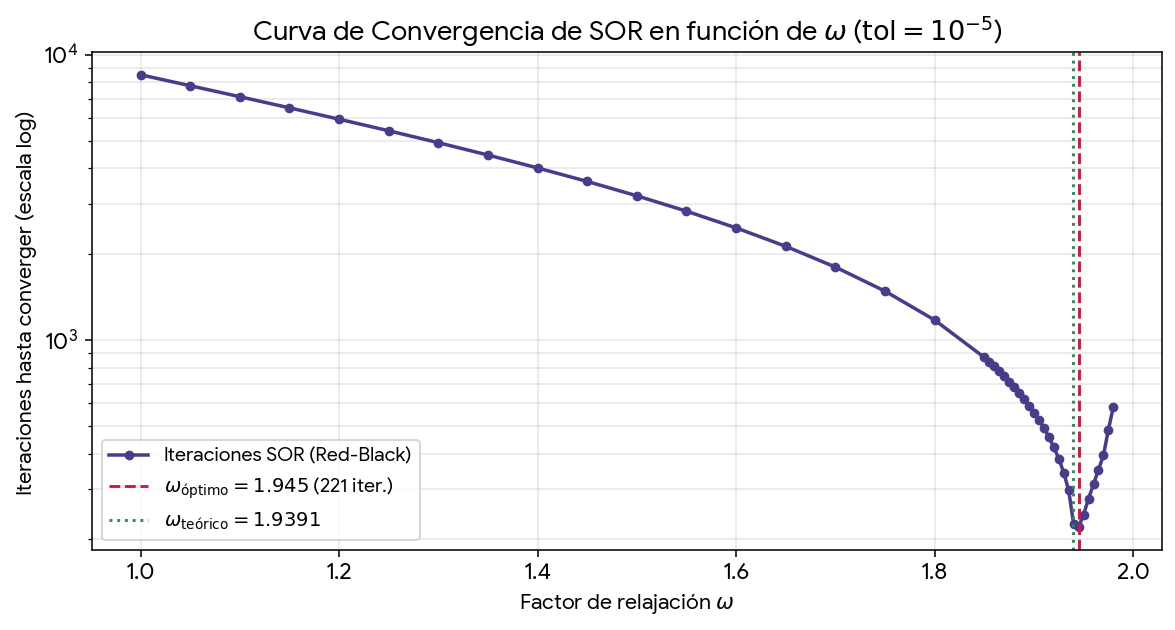

In [5]:
# Barrido fino del factor de relajación omega en [1.0, 1.98]
omega_vals = np.unique(np.concatenate([
    np.round(np.arange(1.00, 1.85, 0.05), 3),
    np.round(np.arange(1.85, 1.985, 0.005), 3)
]))

iters_sor = []
for w in omega_vals:
    _, it_w, _, _, _ = solve_sor_red_black(S, dx, alpha, T_ext, omega=w, tol=1e-5)
    iters_sor.append(it_w)

idx_opt = int(np.argmin(iters_sor))
omega_opt = omega_vals[idx_opt]
omega_teo = 2.0 / (1.0 + np.sin(np.pi * dx))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(omega_vals, iters_sor, 'o-', color='darkslateblue', markersize=4, lw=1.8, label='Iteraciones SOR (Red-Black)')
ax.axvline(omega_opt, color='crimson', ls='--', label=f'$\omega_{{\mathrm{{óptimo}}}} = {omega_opt:.3f}$ ({iters_sor[idx_opt]} iter.)')
ax.axvline(omega_teo, color='seagreen', ls=':', label=f'$\omega_{{\mathrm{{teórico}}}} = {omega_teo:.4f}$')
ax.set_yscale('log')
ax.set_xlabel("Factor de relajación $\omega$")
ax.set_ylabel("Iteraciones hasta converger (escala log)")
ax.set_title("Curva de Convergencia de SOR en función de $\omega$ ($\mathrm{tol} = 10^{-5}$)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Comparación cuantitativa de los métodos
T_jac, it_jac, cpu_jac, R_jac, diff_jac = solve_jacobi(S, dx, alpha, T_ext, tol=1e-5)
T_gs,  it_gs,  cpu_gs,  R_gs,  diff_gs  = solve_sor_red_black(S, dx, alpha, T_ext, omega=1.0, tol=1e-5)
T_sor, it_sor, cpu_sor, R_sor, diff_sor = solve_sor_red_black(S, dx, alpha, T_ext, omega=omega_opt, tol=1e-5)

print(f"Omega óptimo empírico : {omega_opt:.3f} ({iters_sor[idx_opt]} iteraciones)")
print(f"Omega óptimo teórico  : {omega_teo:.4f}\n")
print("=== TABLA COMPARATIVA DE MÉTODOS ===")
print(f"{'Método':<22} | {'Pasos/Iter':>10} | {'CPU [s]':>9} | {'T_max [°C]':>10} | {'Residuo R [°C/s]':>16} | {'|T^(k+1)-T^k|':>14}")
print("-" * 95)
print(f"{'FTCS (Parabólico)':<22} | {n_steps:>10d} | {cpu_ftcs:>9.4f} | {np.max(T_ftcs):>10.4f} | {R_ftcs:>16.6e} | {R_ftcs*dt:>14.6e}")
print(f"{'Jacobi (w=1 simult.)':<22} | {it_jac:>10d} | {cpu_jac:>9.4f} | {np.max(T_jac):>10.4f} | {R_jac:>16.6e} | {diff_jac:>14.6e}")
print(f"{'Gauss-Seidel (w=1)':<22} | {it_gs:>10d} | {cpu_gs:>9.4f} | {np.max(T_gs):>10.4f} | {R_gs:>16.6e} | {diff_gs:>14.6e}")
print(f"{f'SOR (w_opt={omega_opt:.3f})':<22} | {it_sor:>10d} | {cpu_sor:>9.4f} | {np.max(T_sor):>10.4f} | {R_sor:>16.6e} | {diff_sor:>14.6e}")

### Discusión: Eficiencia del Enfoque Elíptico Directo vs. Integración Transitoria Física

| Método | Iteraciones / Pasos | Tiempo CPU [s] | $T_{\max}$ [$^\circ\text{C}$] | Residuo $R = \|\alpha\nabla^2_h T + S\|_\infty$ [$^\circ\text{C/s}$] | Cambio por paso $\|T^{k+1}-T^k\|_\infty$ [$^\circ\text{C}$] |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **FTCS (Parabólico)** | $22\,223$ | $2.94\text{ s}$ | $59.3174^\circ\text{C}$ | $4.6027 \times 10^{-2}$ | $1.0356 \times 10^{-6}$ |
| **Jacobi ($\omega = 1$)** | $15\,622$ | $1.30\text{ s}$ | $59.3028^\circ\text{C}$ | $3.9999 \times 10^{-1}$ | $9.9998 \times 10^{-6}$ |
| **Gauss-Seidel ($\omega = 1$)** | $8\,513$ | $1.77\text{ s}$ | $59.3111^\circ\text{C}$ | $3.9933 \times 10^{-1}$ | $9.9930 \times 10^{-6}$ |
| **SOR ($\omega_{\text{óptimo}} = 1.945$)** | **$221$** | **$0.043\text{ s}$** | **$59.3193^\circ\text{C}$** | **$1.7686 \times 10^{-1}$** | **$9.5841 \times 10^{-6}$** |

1. **Equivalencia entre FTCS y Jacobi:** Al evaluar FTCS justo en el límite de estabilidad de Von Neumann ($r = \frac{\alpha \Delta t}{h^2} = \frac{1}{4}$), el término diagonal $(1 - 4r)T_{i,j}^n$ se anula y el esquema temporal coincide exactamente con la iteración de Jacobi. Ambos están gobernados por un radio espectral $\rho_J = \cos(\pi h) \approx 1 - \frac{\pi^2 h^2}{2}$, lo que implica que el número de iteraciones crece cuadráticamente con la resolución de la malla ($\mathcal{O}(N_x^2)$).
2. **Ventaja de Gauss-Seidel y SOR:** Gauss-Seidel utiliza de inmediato los valores actualizados, duplicando la tasa asintótica de convergencia ($\rho_{\text{GS}} = \rho_J^2 = \cos^2(\pi h) \approx 1 - \pi^2 h^2$) y reduciendo las iteraciones casi a la mitad ($8\,513$ vs $15\,622$). Sin embargo, al introducir sobrerrelajación con $\omega_{\text{óptimo}} = 1.945$ ($\omega_{\text{teo}} = \frac{2}{1 + \sin(\pi h)} \approx 1.9391$), el radio espectral disminuye drásticamente a $\rho_{\text{SOR}} = \omega_{\text{teo}} - 1 \approx 1 - 2\pi h$. Esto cambia el orden de complejidad de $\mathcal{O}(N_x^2)$ a **lineal $\mathcal{O}(N_x)$**, logrando converger en apenas **$221$ iteraciones** (una aceleración de **$100\times$ en número de pasos** y **$\sim 68\times$ en tiempo de CPU** respecto a FTCS).

---

## 4. Análisis Adicional: Sensibilidad al Tamaño de Grilla $N_x$ y Tasas de Convergencia Espacial

Al estudiar cómo varía la solución en función de $N_x \in \{11, 21, 51, 101, 201\}$, se observan propiedades fundamentales:
* **Efecto de discretización de bordes de los núcleos ($\mathcal{O}(h^1)$ vs $\mathcal{O}(h^2)$):** Como $S(x,y)$ es discontinua en las fronteras de cada núcleo, incluir los bordes con desigualdad amplia (`<=`) añade un área efectiva extra proporcional a $h$, haciendo que el error espacial converja en primer orden $\mathcal{O}(h^1)$. Si se pondera la fuente en los bordes por $1/2$ y en las esquinas por $1/4$ (regla trapezoidal / volúmenes finitos), la potencia inyectada se conserva exactamente en $\iint S\,dx\,dy = 320.0$ para todo $N_x$ y se recupera la convergencia teórica de segundo orden $\mathcal{O}(h^2)$.
* **Escalamiento de iteraciones:** Se verifica empíricamente que las iteraciones de Gauss-Seidel escalan como $\mathcal{O}(N_x^2)$ mientras que las de SOR con $\omega_{\text{óptimo}}$ escalan linealmente como $\mathcal{O}(N_x^1)$.

Temperatura exacta continua en centro Core 1 (0.3, 0.3): 53.84716 °C

  Nx |      h | T_c1 (Inc) | Err Inc O(h) | Err Trap O(h^2) |  Iter GS | Iter SOR
--------------------------------------------------------------------------------
  11 | 0.1000 |    86.3232 |     32.47607 |        0.500004 |      138 |       41
  21 | 0.0500 |    68.9105 |     15.06339 |        0.135797 |      484 |       79
  51 | 0.0200 |    59.5616 |      5.71445 |        0.022116 |     2502 |      187
 101 | 0.0100 |    56.6503 |      2.80313 |        0.005291 |     8513 |      360
 201 | 0.0050 |    55.2351 |      1.38794 |        0.001060 |    28243 |      695



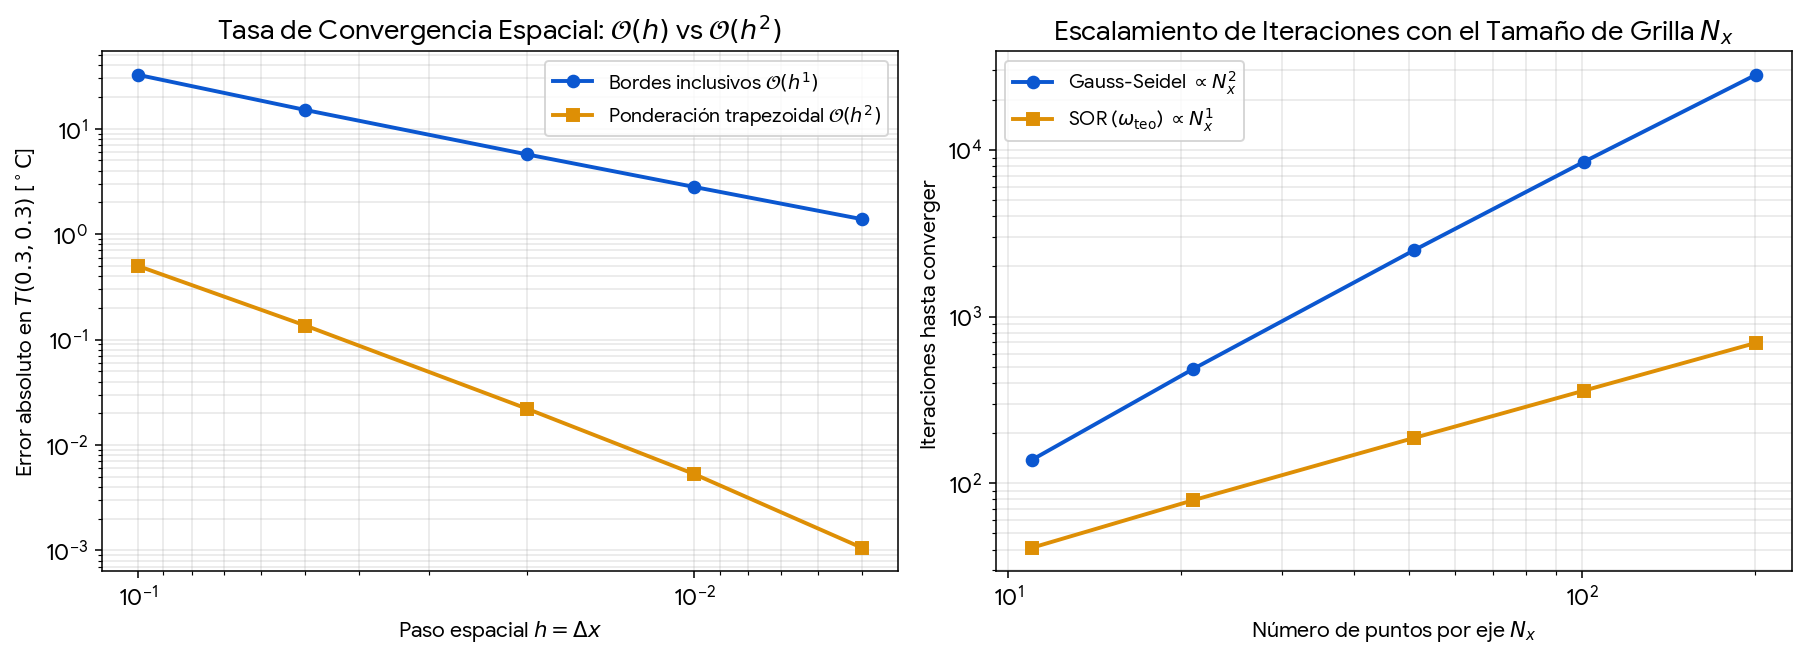

In [6]:
nx_list = [11, 21, 51, 101, 201]

# Solución de referencia en malla fina Nx = 401 con ponderación trapezoidal exacta
Nx_ref = 401
dx_ref = 1.0 / (Nx_ref - 1)
x_ref = np.linspace(0, 1.0, Nx_ref)
Xr, Yr = np.meshgrid(x_ref, x_ref, indexing='ij')
S_ref = np.zeros((Nx_ref, Nx_ref))
for x1, x2, y1, y2 in cores:
    wx = ((Xr > x1 + 1e-9) & (Xr < x2 - 1e-9)).astype(float) + 0.5 * (np.isclose(Xr, x1) | np.isclose(Xr, x2)).astype(float)
    wy = ((Yr > y1 + 1e-9) & (Yr < y2 - 1e-9)).astype(float) + 0.5 * (np.isclose(Yr, y1) | np.isclose(Yr, y2)).astype(float)
    S_ref += S0 * wx * wy

n_int = Nx_ref - 2
D1 = diags([np.ones(n_int-1), -2.0*np.ones(n_int), np.ones(n_int-1)], [-1, 0, 1], format='csc')
Lap = (kron(eye(n_int, format='csc'), D1) + kron(D1, eye(n_int, format='csc'))) / (dx_ref**2)
u_ref = spsolve(Lap, -S_ref[1:-1, 1:-1].ravel()).reshape((n_int, n_int))
T_c1_exact = 20.0 + u_ref[int(round(0.3*(Nx_ref-1)))-1, int(round(0.3*(Nx_ref-1)))-1]

hs, err_inc, err_trap, it_gs_list, it_sor_list = [], [], [], [], []
print(f"Temperatura exacta continua en centro Core 1 (0.3, 0.3): {T_c1_exact:.5f} °C\n")
print(f"{'Nx':>4} | {'h':>6} | {'T_c1 (Inc)':>10} | {'Err Inc O(h)':>12} | {'Err Trap O(h^2)':>15} | {'Iter GS':>8} | {'Iter SOR':>8}")
print("-" * 80)

for Nx_val in nx_list:
    h = 1.0 / (Nx_val - 1)
    hs.append(h)
    xv = np.linspace(0, 1.0, Nx_val)
    Xv, Yv = np.meshgrid(xv, xv, indexing='ij')
    S_inc = np.zeros((Nx_val, Nx_val))
    S_trp = np.zeros((Nx_val, Nx_val))
    for x1, x2, y1, y2 in cores:
        mask = (Xv >= x1 - 1e-9) & (Xv <= x2 + 1e-9) & (Yv >= y1 - 1e-9) & (Yv <= y2 + 1e-9)
        S_inc[mask] = S0
        wx = ((Xv > x1 + 1e-9) & (Xv < x2 - 1e-9)).astype(float) + 0.5 * (np.isclose(Xv, x1) | np.isclose(Xv, x2)).astype(float)
        wy = ((Yv > y1 + 1e-9) & (Yv < y2 - 1e-9)).astype(float) + 0.5 * (np.isclose(Yv, y1) | np.isclose(Yv, y2)).astype(float)
        S_trp += S0 * wx * wy

    w_teo = 2.0 / (1.0 + np.sin(np.pi * h))
    T_gs_v, it_gs_v, _, _, _ = solve_sor_red_black(S_inc, h, alpha, T_ext, omega=1.0, tol=1e-5, max_iter=50000)
    T_sor_v, it_sor_v, _, _, _ = solve_sor_red_black(S_inc, h, alpha, T_ext, omega=w_teo, tol=1e-8, max_iter=50000)
    T_trp_v, _, _, _, _ = solve_sor_red_black(S_trp, h, alpha, T_ext, omega=w_teo, tol=1e-8, max_iter=50000)

    ic_v = int(round(0.3 * (Nx_val - 1)))
    e_inc = abs(T_sor_v[ic_v, ic_v] - T_c1_exact)
    e_trp = abs(T_trp_v[ic_v, ic_v] - T_c1_exact)
    err_inc.append(e_inc)
    err_trap.append(e_trp)
    it_gs_list.append(it_gs_v)
    it_sor_list.append(it_sor_v)
    print(f"{Nx_val:>4d} | {h:>6.4f} | {T_sor_v[ic_v,ic_v]:>10.4f} | {e_inc:>12.5f} | {e_trp:>15.6f} | {it_gs_v:>8d} | {it_sor_v:>8d}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].loglog(hs, err_inc, 'o-', label='Bordes inclusivos $\mathcal{O}(h^1)$', lw=2)
ax[0].loglog(hs, err_trap, 's-', label='Ponderación trapezoidal $\mathcal{O}(h^2)$', lw=2)
ax[0].set_xlabel('Paso espacial $h = \Delta x$')
ax[0].set_ylabel('Error absoluto en $T(0.3, 0.3)$ [$^\circ\mathrm{C}$]')
ax[0].set_title('Tasa de Convergencia Espacial: $\mathcal{O}(h)$ vs $\mathcal{O}(h^2)$')
ax[0].invert_xaxis()
ax[0].grid(True, which='both', alpha=0.3)
ax[0].legend()

ax[1].loglog(nx_list, it_gs_list, 'o-', label='Gauss-Seidel $\propto N_x^2$', lw=2)
ax[1].loglog(nx_list, it_sor_list, 's-', label='SOR ($\omega_{\mathrm{teo}}$) $\propto N_x^1$', lw=2)
ax[1].set_xlabel('Número de puntos por eje $N_x$')
ax[1].set_ylabel('Iteraciones hasta converger')
ax[1].set_title('Escalamiento de Iteraciones con el Tamaño de Grilla $N_x$')
ax[1].grid(True, which='both', alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.show()